# Sections 4.3.4-4.3.5; Figure 8A-C

**Reference:** Version_3_submitted.

Repeated holdout TDA/SVM, single-neuron comparison, and neuron-label shuffling. Cached scores are included; raw GC recordings and Bayesian single-neuron scores are external inputs.

Run the setup cell first. Generated figures go to `outputs/figures/sec04_03_04-05_fig08_gustatory_cortex_classification/`; generated arrays and templates go to `outputs/generated/`. Existing saved outputs are preserved historical outputs, not evidence of a fresh run. See the root README and `docs/REPRODUCIBILITY.md`.


In [ ]:
# Resolve paths from the repository root or any notebook subdirectory.
from pathlib import Path
import os
import sys

REPO_ROOT = next(p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
                 if (p / "repo_paths.py").is_file() and (p / "environment.yml").is_file())
os.chdir(REPO_ROOT)
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))
from repo_paths import (GC_NEURON_DF, GC_SINGLE_NEURON_SCORES, CRCNS_ARCHIVE,
                        LEGACY_DATA_DIR, LEGACY_CODE_DIR, GENERATED_DATA_DIR)
if LEGACY_CODE_DIR is not None and str(LEGACY_CODE_DIR) not in sys.path:
    sys.path.insert(0, str(LEGACY_CODE_DIR))
FIGURE_DIR = REPO_ROOT / "outputs" / "figures" / "sec04_03_04-05_fig08_gustatory_cortex_classification"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
GENERATED_DATA_DIR.mkdir(parents=True, exist_ok=True)


# Application to Gustatory Cortex Recordings

In [2]:
from utils import *

In [3]:
import pandas as pd
import pickle
path_neuron_df = GC_NEURON_DF
pairs = pd.read_csv('data/metadata/pairs.csv',dtype= {'Date':str}) # pairs is a csv file that helps keep a fixed order for Mouse-Date pairs
with open(path_neuron_df,'rb') as file:
    Df = pickle.load(file)

In [4]:

# helper functions to work with Df
def get_raster(Mouse,Date,Taste,Trial,time_interval = [0,4000]):
    """
    INPUT:
    1) Mouse = str
    2) Date = str
    3) Taste = int
    4) Trial = int
    5) time_interval = list with two entries. It will tell the min and max time to look at in the raster. Set to 0ms - 4000ms by default.
    OUTPUT: numpy array. Will extract from Df the specified raster plot
    """
    frame = Df[(Df['MouseID'] == Mouse) & (Df['Date'] == Date) & (Df['Taste'] == Taste) & (Df['Trial'] == Trial)].iloc[:,7:] # Column 7 and on is spike train
    frame_array = np.array(frame) # turn it into a numpy array. This represents the whole 4000ms
    
    #### Extract the time interval specified ####
    time_begin = time_interval[0]
    time_end = time_interval[1]
    
    frame_array = frame_array[:,time_begin:time_end] # update the frame_array to extract the specified time interval

    return frame_array

def get_dates(Mouse):
    """
    INPUT:
    Mouse = str
    OUTPUT: numpy array consisting of dates the given mouse had trials
    """
     # get dates
    out = Df[(Df['MouseID'] == Mouse) & (Df['Taste'] == 0)]['Date'].unique() # This is taste independent. So, we will pick taste 0 as a representative.
    return out

def get_trial(Mouse, Date, Taste):
    """
    INPUT: 
    Mouse
    Date
    Taste
    OUTPUT:
    Number of trials
    """
    out = Df[(Df['MouseID'] == Mouse) & (Df['Date'] == Date) &(Df['Taste'] == Taste)]['Trial'].unique()
    return(len(out))  


def get_neurons(Mouse, Date):
    """
    Input
    Mouse: str
    Date: str 
    Returns
    Neurons that belong to the Mouse-Date pair 
    """
    row_mask = (Df["MouseID"] == Mouse) & (Df["Date"] == Date)
    neurons = np.unique(np.array(Df[row_mask]["Neuron"]))
    return neurons

def get_trial_from_neuron(neuron,taste,time_interval = [2000,4000]):
    """
    Input
    neuron: int -- neuron id index in Df
    taste: int -- 0, 1 or 2.
    time_interval = [2000,4000] by default
    Returns:
    array -- Returns all trials from the neuron-taste pair. array has shape (# of trials, end_time - begin_time)
    """
    row_mask = (Df["Neuron"] == neuron) & (Df["Taste"] == taste)
    trials = np.array(Df[row_mask].iloc[:,7:])
    begin_time = time_interval[0]
    end_time = time_interval[1]
    array = np.array(trials)[:,begin_time:end_time]

    return array

In [5]:
# Map Mouse-Date-Taste (MDT) to all of its corresponding rasters/trials
MDT_to_trials = {}             
for _, row in pairs.iterrows():
    Mouse = row["Mouse"]
    Date = row["Date"]

    for Taste in (0, 1, 2):
        # Assuming get_trial returns an integer count of trials
        n_trials = get_trial(Mouse=Mouse, Date=Date, Taste=Taste)

        raster_list = []
      

        for j in range(n_trials):
            # Fetch raster: Shape is likely (N_neurons, N_timepoints)
            raster = get_raster(Mouse=Mouse, Date=Date, Taste=Taste, Trial=j, time_interval=[2000, 4000])
            raster_list.append(raster)

        # Store
        MDT_to_trials[(Mouse, Date, Taste)] = raster_list

In [16]:

MDT_to_number_of_trials = {MDT: len(trials) for MDT, trials in MDT_to_trials.items()}
# display this as a pandas dataframe for better visualization
MDT_to_number_of_trials_df = pd.DataFrame(list(MDT_to_number_of_trials.items()), columns=['Mouse-Date-Taste', 'Number of Trials'])
# Display all rows
with pd.option_context("display.max_rows", None):
    display(MDT_to_number_of_trials_df)

# Save as CSV
MDT_to_number_of_trials_df.to_csv(
    'data/metadata/MDT_to_number_of_trials.csv',
    index=False
)
min_trials = MDT_to_number_of_trials_df["Number of Trials"].min()
max_trials = MDT_to_number_of_trials_df["Number of Trials"].max()

print(f"Each Mouse-Date-Taste has between {min_trials} and {max_trials} available trials.")

,Mouse-Date-Taste,Number of Trials
0,"(CB279, 121621, 0)",30
1,"(CB279, 121621, 1)",30
2,"(CB279, 121621, 2)",30
3,"(CB279, 121421, 0)",23
4,"(CB279, 121421, 1)",29
5,"(CB279, 121421, 2)",30
6,"(CB279, 122021, 0)",30
7,"(CB279, 122021, 1)",29
8,"(CB279, 122021, 2)",30
9,"(CB278, 121521, 0)",29


Each Mouse-Date-Taste has between 16 and 30 available trials.


In [7]:
from scipy.ndimage import gaussian_filter
MDT_to_smoothed_trials = {} # map (Mouse,Date,Taste) to smoothed trials

sigma = 30 # gaussian smoothing parameter

for _, row in pairs.iterrows():
    Mouse = row["Mouse"]
    Date = row["Date"]

    for Taste in (0, 1, 2):
        # Assuming get_trial returns an integer count of trials
        n_trials = get_trial(Mouse=Mouse, Date=Date, Taste=Taste)

        raster_list = []
        raster_vec_list = []
        # We need a list to store the smoothed trials for this specific (M, D, T)
        raster_smooth_list = [] 

        for j in range(n_trials):
            # Fetch raster: Shape is (N_neurons, N_timepoints)
            raster = get_raster(Mouse=Mouse, Date=Date, Taste=Taste, Trial=j, time_interval=[2000, 4000])
            
            # Smooth the raster
            # sigma=(0, sigma) ensures we only smooth along time (axis 1), NOT across neurons (axis 0)
            smoothed_raster = gaussian_filter(raster.astype(float), sigma=(0, sigma))
            
            # Store the flattened version of the smoothed raster
            raster_smooth_list.append(smoothed_raster.flatten())

        # Save the smoothed list to the dictionary
        MDT_to_smoothed_trials[(Mouse, Date, Taste)] = raster_smooth_list

In [10]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

def make_xy_svm(Mouse, Date, tastes=(0, 1, 2)):
    X_list = []
    y_list = []

    for Taste in tastes:
        trials_vec = MDT_to_smoothed_trials.get((Mouse,Date,Taste),[])
        for vec in trials_vec:
            X_list.append(vec)
            y_list.append(Taste)

    if len(X_list) == 0:
        return None, None

    lengths = [len(v) for v in X_list]
    if len(set(lengths)) != 1:
        raise ValueError(
            f"Inconsistent feature lengths for Mouse={Mouse}, Date={Date}. "
            f"Unique lengths={sorted(set(lengths))[:5]}..."
        )

    X = np.vstack(X_list)
    y = np.array(y_list)
    return X, y



def svm_score_rhv(Mouse, Date, tastes=(0, 1, 2), C=1.0,
                  n_repeats=20, test_size=0.3, random_state=42,return_splits = False):
    X, y = make_xy_svm(Mouse, Date, tastes=tastes)
    if X is None:
        return np.nan, {}

    classes, counts = np.unique(y, return_counts=True)
    counts_dict = dict(zip(classes, counts))
    if counts.min() < 2:
        return np.nan, counts_dict

    model = make_pipeline(
        StandardScaler(with_mean=True),
        SVC(kernel="linear", C=C),
    )

    splitter = StratifiedShuffleSplit(
        n_splits=n_repeats, test_size=test_size, random_state=random_state
    )

    scores = []
    for train_idx, test_idx in splitter.split(X, y):
        model.fit(X[train_idx], y[train_idx])
        preds = model.predict(X[test_idx])
        scores.append(accuracy_score(y[test_idx], preds))

    if return_splits:
        return np.mean(scores), scores
    else:
        return np.mean(scores)





In [6]:
from sklearn.model_selection import StratifiedShuffleSplit
from tqdm import tqdm
from sklearn.metrics import accuracy_score
from sklearn.neighbors import KNeighborsClassifier

def rasters_to_barcode(list_of_rasters, dim = 0):
    list_of_barcodes = []
    for raster in list_of_rasters:
        vp_dm = VP_trivial(raster)
        dgm = ripser(vp_dm,distance_matrix= True)['dgms'][dim]
        list_of_barcodes.append(dgm)

    return list_of_barcodes

def tda_rhv(rasters,labels,dim = 0,n_repeats = 20, test_size = 0.3, random_state = 42,return_splits = False): # TDA pipeline with repeated holdout validation (rhv)

    X_barcodes = rasters_to_barcode(X_rasters,dim = dim)
    n = len(X_barcodes)
    BDM = np.zeros((n, n), dtype=float)
    for i in range(n):
        for j in range(i + 1, n):
            if dim == 0:
                d = bottleneck_zero(X_barcodes[i], X_barcodes[j]) 
            else:
                d = persim.bottleneck(X_barcodes[i],X_barcodes[j])
            
            BDM[i, j] = d
            BDM[j, i] = d

    splitter = StratifiedShuffleSplit(
        n_splits=n_repeats, test_size=test_size, random_state=random_state
    )

    scores = []
    for train_idx, test_idx in splitter.split(np.zeros_like(y), y):
        D_train = BDM[np.ix_(train_idx, train_idx)]
        D_test = BDM[np.ix_(test_idx, train_idx)]

        knn = KNeighborsClassifier(n_neighbors=1, metric="precomputed")
        knn.fit(D_train, y[train_idx])
        preds = knn.predict(D_test)

        scores.append(accuracy_score(y[test_idx], preds))

    mean_score = np.mean(scores) 
    if return_splits:
        return mean_score, scores
    else:
        return mean_score

# 3-class run

In [11]:
# run a for loop to iterate through all Mouse-Date pairs
# as you do so, save the information in a pandas data frame
# first we do 3-class classification
results_list_3class = []
for index, row in tqdm(pairs.iterrows(), total=pairs.shape[0]):
    Mouse = row['Mouse']
    Date = row['Date']

    stim_0_trials = MDT_to_trials[(Mouse, Date, 0)]
    stim_1_trials = MDT_to_trials[(Mouse, Date, 1)]
    stim_2_trials = MDT_to_trials[(Mouse, Date, 2)]

    X_rasters = stim_0_trials + stim_1_trials + stim_2_trials
    y = np.array(
        [0] * len(stim_0_trials) +
        [1] * len(stim_1_trials) +
        [2] * len(stim_2_trials)
    )
    
    # TDA
    mean_score_tda, scores_tda = tda_rhv(X_rasters,y,return_splits= True)

    # SVM
    mean_score_svm, scores_svm = svm_score_rhv(Mouse, Date, return_splits=True)

    row_dict = {
        'Mouse': Mouse,
        'Date': Date,
        'TDA_Mean': mean_score_tda,
        'SVM_Mean': mean_score_svm
    }

    for i, score in enumerate(scores_tda):
        row_dict[f'TDA_Split_{i+1}'] = score
    for i, score in enumerate(scores_svm):
        row_dict[f'SVM_Split_{i+1}'] = score

    results_list_3class.append(row_dict)
    
    
MD_scores_table_3class = pd.DataFrame(results_list_3class)

MD_scores_table_3class.to_csv('results/gustatory_cortex/tda_svm_scores_3class.csv', index=False)

100%|██████████| 38/38 [01:59<00:00,  3.14s/it]


In [12]:
MD_scores_table_3class.head()

,Mouse,Date,TDA_Mean,SVM_Mean,TDA_Split_1,TDA_Split_2,TDA_Split_3,TDA_Split_4,TDA_Split_5,TDA_Split_6,...,SVM_Split_11,SVM_Split_12,SVM_Split_13,SVM_Split_14,SVM_Split_15,SVM_Split_16,SVM_Split_17,SVM_Split_18,SVM_Split_19,SVM_Split_20
0,CB279,121621,0.511111,0.681481,0.518519,0.555556,0.444444,0.555556,0.555556,0.555556,...,0.629630,0.740741,0.777778,0.592593,0.629630,0.703704,0.629630,0.703704,0.629630,0.851852
1,CB279,121421,0.476000,0.800000,0.520000,0.560000,0.640000,0.440000,0.360000,0.560000,...,0.840000,0.840000,0.920000,0.880000,0.720000,0.680000,0.880000,0.720000,0.640000,0.840000
2,CB279,122021,0.603704,0.583333,0.666667,0.592593,0.629630,0.592593,0.481481,0.629630,...,0.444444,0.629630,0.592593,0.481481,0.740741,0.555556,0.740741,0.555556,0.407407,0.555556
3,CB278,121521,0.458333,0.787500,0.416667,0.583333,0.541667,0.333333,0.500000,0.541667,...,0.875000,0.708333,0.833333,0.791667,0.875000,0.833333,0.625000,0.708333,0.750000,0.833333
4,CB278,121721,0.477778,0.762963,0.518519,0.444444,0.518519,0.518519,0.370370,0.407407,...,0.851852,0.703704,0.814815,0.814815,0.814815,0.777778,0.666667,0.814815,0.777778,0.703704


# 2-Class run

In [13]:
results_list_2class = []
for index, row in tqdm(pairs.iterrows(), total=pairs.shape[0]):
    Mouse = row['Mouse']
    Date = row['Date']

    stim_0_trials = MDT_to_trials[(Mouse, Date, 0)]
    stim_1_trials = MDT_to_trials[(Mouse, Date, 1)]
    # stim_2_trials = MDT_to_trials[(Mouse, Date, 2)]

    X_rasters = stim_0_trials + stim_1_trials
    y = np.array(
        [0] * len(stim_0_trials) +
        [1] * len(stim_1_trials)
    )
    
    # TDA
    mean_score_tda, scores_tda = tda_rhv(X_rasters,y,return_splits= True)

    # SVM
    mean_score_svm, scores_svm = svm_score_rhv(Mouse, Date, tastes = (0,1), return_splits=True)

    row_dict = {
        'Mouse': Mouse,
        'Date': Date,
        'TDA_Mean': mean_score_tda,
        'SVM_Mean': mean_score_svm
    }

    for i, score in enumerate(scores_tda):
        row_dict[f'TDA_Split_{i+1}'] = score
    for i, score in enumerate(scores_svm):
        row_dict[f'SVM_Split_{i+1}'] = score

    results_list_2class.append(row_dict)
    
    
MD_scores_table_2class = pd.DataFrame(results_list_2class)

MD_scores_table_2class.to_csv('results/gustatory_cortex/tda_svm_scores_2class.csv', index=False)

100%|██████████| 38/38 [00:47<00:00,  1.25s/it]


In [14]:
MD_scores_table_2class.head()

,Mouse,Date,TDA_Mean,SVM_Mean,TDA_Split_1,TDA_Split_2,TDA_Split_3,TDA_Split_4,TDA_Split_5,TDA_Split_6,...,SVM_Split_11,SVM_Split_12,SVM_Split_13,SVM_Split_14,SVM_Split_15,SVM_Split_16,SVM_Split_17,SVM_Split_18,SVM_Split_19,SVM_Split_20
0,CB279,121621,0.733333,0.858333,0.722222,0.833333,0.611111,0.666667,0.888889,0.722222,...,0.944444,0.777778,0.833333,0.944444,0.888889,0.888889,0.888889,0.833333,0.944444,0.833333
1,CB279,121421,0.668750,0.937500,0.750000,0.687500,0.625000,0.687500,0.625000,0.625000,...,0.937500,0.812500,1.000000,1.000000,0.937500,0.937500,0.937500,0.937500,1.000000,0.875000
2,CB279,122021,0.850000,0.788889,0.888889,0.833333,0.777778,0.833333,0.833333,0.888889,...,0.777778,0.833333,0.888889,0.833333,0.722222,0.777778,0.555556,0.722222,0.777778,0.888889
3,CB278,121521,0.816667,0.906667,0.800000,0.866667,0.733333,0.800000,0.733333,0.933333,...,0.866667,0.800000,0.800000,0.866667,1.000000,0.800000,0.933333,1.000000,0.866667,0.933333
4,CB278,121721,0.830556,0.938889,0.833333,0.888889,0.777778,0.833333,0.833333,0.833333,...,0.944444,1.000000,1.000000,0.944444,1.000000,1.000000,0.888889,1.000000,0.944444,0.833333


# Single neurons

In [15]:
single_neuron_scores_path = GC_SINGLE_NEURON_SCORES
single_neuron_scores = pd.read_csv(single_neuron_scores_path,dtype= {"Date":str},keep_default_na= False)

# Map each MD pair to a tuple (x,y) where x is top neuron score and y is the average neuron score
MD_to_ind_neuron_scores = {}
for _, row in pairs.iterrows():
    m = row['Mouse']
    d = row['Date']

    all_neuron_scores = list(single_neuron_scores[(single_neuron_scores['MouseID'] == m) &
                                             (single_neuron_scores['Date'] == d)
                                             ]['SNAscore'])
    MD_to_ind_neuron_scores[(m,d)] = all_neuron_scores


    

In [16]:
# example for MD to ind neuron scores
MD_to_ind_neuron_scores[('CB280','121521')]


[0.6,
 0.8549019607843137,
 0.403921568627451,
 0.6313725490196078,
 0.5568627450980392,
 0.5019607843137255]


# Plots

In [ ]:
# prepare data for plotting
from functools import reduce
# prep TDA data
df_TDA_3class = pd.read_csv('results/gustatory_cortex/tda_scores_rhv_3class.csv')
df_TDA_2class = pd.read_csv('results/gustatory_cortex/tda_scores_rhv_2class.csv')

# prep SVM data
df_SVM_3class = pd.read_csv('results/gustatory_cortex/SVM_smoothed_rhv_3class.csv')
df_SVM_2class = pd.read_csv('results/gustatory_cortex/SVM_smoothed_rhv_2class.csv')


# merge all data into one dataframe

# 1. Format the 'Date' column in all dataframes to have leading zeros
for df in [df_TDA_3class, df_TDA_2class, df_SVM_3class, df_SVM_2class]:
    df['Date'] = df['Date'].astype(str).str.zfill(6)



In [ ]:
# Rename columns for the final merged dataframe
tda3 = df_TDA_3class[['Mouse', 'Date', 'TDA Score']].rename(columns={'TDA Score': 'TDA 3-class'})
tda2 = df_TDA_2class[['Mouse', 'Date', 'TDA Score']].rename(columns={'TDA Score': 'TDA 2-class'})
svm3 = df_SVM_3class[['Mouse', 'Date', 'SVM Score']].rename(columns={'SVM Score': 'SVM 3-class'})
svm2 = df_SVM_2class[['Mouse', 'Date', 'SVM Score']].rename(columns={'SVM Score': 'SVM 2-class'})

# 2. Compile the prepared dataframes into a list
dataframes_to_merge = [tda3, tda2, svm3, svm2]

# 3. Merge all dataframes on 'Mouse' and 'Date'
merged_df = reduce(lambda left, right: pd.merge(left, right, on=['Mouse', 'Date'], how='inner'), dataframes_to_merge)


# Create the Experiment label (Mouse-Date)
merged_df['Experiment'] = merged_df['Mouse'] + '-' + merged_df['Date']

# Add columns for individual neuron scores average
def get_avg_ind_score(row):
    key = (row['Mouse'], row['Date'])
    if key in MD_to_ind_neuron_scores:
        return np.mean(MD_to_ind_neuron_scores[key])
    return np.nan

merged_df['Avg Ind Score'] = merged_df.apply(get_avg_ind_score, axis=1)
merged_df.head()

In [ ]:
# 1. Sort the dataframe by 'TDA 3-class' descending before plotting
merged_df = merged_df.sort_values(by='TDA 3-class', ascending=False).reset_index(drop=True)

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Sort the dataframe by 'TDA 3-class' descending before plotting
merged_df = merged_df.sort_values(by='TDA 3-class', ascending=False).reset_index(drop=True)

# 2. Set up the figure with two subplots sharing the x-axis
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(28, 20), sharex=True)
plt.subplots_adjust(hspace=0.1) # Reduce space between plots

# X-axis data for alignment (now sorted)
experiments = merged_df['Experiment']
x_ticks = np.arange(len(experiments))

# --- Plot 1: 3-class data ---
ax1.set_title('3-Class Classification Performance')
ax1.set_ylabel('Classification Score')
ax1.set_ylim(0, 1)
ax1.grid(axis='both', linestyle='-', alpha=0.3)

# Define reference lines
chance_3class = 1/3
ax1.axhline(y=chance_3class, color='black', linestyle='--')

# Plot Individual Neuron Scores (gray dots) and Average (black dot) for 3-class
for i, exp in enumerate(experiments):
    mouse = merged_df.iloc[i]['Mouse']
    date = merged_df.iloc[i]['Date']
    key = (mouse, date)
    
    if key in MD_to_ind_neuron_scores:
        scores = MD_to_ind_neuron_scores[key]
        x_values = [i] * len(scores) # All scores for this exp align vertically
        
        # Plot individual gray dots (only once per legend entry)
        if i == 0:
            ax1.scatter(x_values, scores, color='gray', alpha=0.5, s=20, label='Ind. Neuron Scores')
        else:
            ax1.scatter(x_values, scores, color='gray', alpha=0.5, s=20)

# Plot Average Ind Neuron Score (black dot, slightly larger)
ax1.scatter(x_ticks, merged_df['Avg Ind Score'], color='black', s=60, label='Avg. Ind Neuron Score')

# Plot TDA 3-class (orange dot)
ax1.scatter(x_ticks, merged_df['TDA 3-class'], color='orange', marker='o', s=80, label='TDA')

# Plot SVM 3-class (black 'x')
ax1.scatter(x_ticks, merged_df['SVM 3-class'], color='black', marker='x', s=80, label='SVM')

ax1.legend(loc='upper right', bbox_to_anchor=(1, 1), fontsize='small')


# --- Plot 2: 2-class data ---
ax2.set_title('2-Class Classification Performance')
ax2.set_ylabel('Classification Score')
ax2.set_xlabel('Experiment (Mouse-Date)')
ax2.set_ylim(0, 1)
ax2.grid(axis='both', linestyle='-', alpha=0.3)

# Define reference lines
chance_2class = 1/2
ax2.axhline(y=chance_2class, color='black', linestyle='--')

# Plot TDA 2-class (orange dot)
ax2.scatter(x_ticks, merged_df['TDA 2-class'], color='orange', marker='o', s=80, label='TDA')

# Plot SVM 2-class (black 'x')
ax2.scatter(x_ticks, merged_df['SVM 2-class'], color='black', marker='x', s=80, label='SVM')

# Formatting x-axis labels (shared across both subplots)
ax2.set_xticks(x_ticks)
ax2.set_xticklabels(experiments, rotation=90) # Rotate for readability
ax2.legend(loc='upper right', bbox_to_anchor=(1, 1))

plt.tight_layout()

# Save the figure as a PDF before displaying
plt.savefig((FIGURE_DIR / 'classification_performance_TDA_SVM.pdf'), format='pdf', bbox_inches='tight')

plt.show()

# Permute Neuron IDs

In [17]:
def permute_neuron_ids(raster):
    """Randomly shuffles the rows (neurons) of a single trial raster."""
    idx = np.random.permutation(raster.shape[0])
    return raster[idx, :]

def get_svm_features(raster, sigma=30):
    """Standard smoothed firing rate features (Flattened)."""
    smoothed = gaussian_filter(raster.astype(float), sigma=(0, sigma))
    return smoothed.flatten()


def evaluate_tda_svm(Mouse, Date, n_repeats=20, test_size=0.3, random_state=42, C=1.0, sigma=30):
    """
    Compare TDA (1-NN on bottleneck distance matrix) vs SVM
    on normal vs neuron-ID-permuted rasters for Taste 0 vs 1.

    Returns
    -------
    pd.DataFrame
        One-row dataframe with summary metrics.
    """
    t0 = MDT_to_trials.get((Mouse, Date, 0), [])
    t1 = MDT_to_trials.get((Mouse, Date, 1), [])
    X_rasters = t0 + t1
    y = np.array([0] * len(t0) + [1] * len(t1))

    # Basic validity checks
    n0, n1 = len(t0), len(t1)
    if n0 < 2 or n1 < 2:
        return pd.DataFrame([{
            "Mouse": Mouse,
            "Date": Date,
            "n_taste0": n0,
            "n_taste1": n1,
            "TDA_normal_mean": np.nan,
            "TDA_normal_std": np.nan,
            "TDA_shuffled_mean": np.nan,
            "TDA_shuffled_std": np.nan,
            "SVM_normal_mean": np.nan,
            "SVM_normal_std": np.nan,
            "SVM_shuffled_mean": np.nan,
            "SVM_shuffled_std": np.nan,
            "Error": "Not enough trials per class (need >=2)."
        }])

    rng = np.random.default_rng(random_state)

    # Features for SVM
    X_svm_norm = np.array([get_svm_features(r, sigma=sigma) for r in X_rasters])

    # Permute neuron IDs per trial (reproducible)
    X_permuted = [r[rng.permutation(r.shape[0]), :] for r in X_rasters]
    X_svm_shuff = np.array([get_svm_features(r, sigma=sigma) for r in X_permuted])

    # Barcodes
    X_barcodes_normal = rasters_to_barcode(X_rasters, dim=0)
    X_barcodes_shuffled = rasters_to_barcode(X_permuted, dim=0)

    # Build bottleneck distance matrices
    n = len(X_barcodes_normal)
    BDM_normal = np.zeros((n, n), dtype=float)
    BDM_shuffled = np.zeros((n, n), dtype=float)

    for i in range(n):
        for j in range(i + 1, n):
            d_norm = bottleneck_zero(X_barcodes_normal[i], X_barcodes_normal[j])
            d_shuf = bottleneck_zero(X_barcodes_shuffled[i], X_barcodes_shuffled[j])

            BDM_normal[i, j] = BDM_normal[j, i] = d_norm
            BDM_shuffled[i, j] = BDM_shuffled[j, i] = d_shuf

    # Splitter / models
    splitter = StratifiedShuffleSplit(
        n_splits=n_repeats, test_size=test_size, random_state=random_state
    )

    svm_model = make_pipeline(
        StandardScaler(with_mean=True),
        SVC(kernel="linear", C=C),
    )
    tda_knn = KNeighborsClassifier(n_neighbors=1, metric="precomputed")

    tda_scores_normal, tda_scores_shuffled = [], []
    svm_scores_normal, svm_scores_shuffled = [], []

    try:
        for train_idx, test_idx in splitter.split(np.zeros_like(y), y):
            # ----- TDA -----
            D_train_norm = BDM_normal[np.ix_(train_idx, train_idx)]
            D_test_norm = BDM_normal[np.ix_(test_idx, train_idx)]
            preds_tda_norm = tda_knn.fit(D_train_norm, y[train_idx]).predict(D_test_norm)
            tda_scores_normal.append(accuracy_score(y[test_idx], preds_tda_norm))

            D_train_shuf = BDM_shuffled[np.ix_(train_idx, train_idx)]
            D_test_shuf = BDM_shuffled[np.ix_(test_idx, train_idx)]
            preds_tda_shuf = tda_knn.fit(D_train_shuf, y[train_idx]).predict(D_test_shuf)
            tda_scores_shuffled.append(accuracy_score(y[test_idx], preds_tda_shuf))

            # ----- SVM -----
            preds_svm_norm = svm_model.fit(
                X_svm_norm[train_idx], y[train_idx]
            ).predict(X_svm_norm[test_idx])
            svm_scores_normal.append(accuracy_score(y[test_idx], preds_svm_norm))

            preds_svm_shuf = svm_model.fit(
                X_svm_shuff[train_idx], y[train_idx]
            ).predict(X_svm_shuff[test_idx])
            svm_scores_shuffled.append(accuracy_score(y[test_idx], preds_svm_shuf))

    except ValueError as e:
        return pd.DataFrame([{
            "Mouse": Mouse,
            "Date": Date,
            "n_taste0": n0,
            "n_taste1": n1,
            "TDA_normal_mean": np.nan,
            "TDA_normal_std": np.nan,
            "TDA_shuffled_mean": np.nan,
            "TDA_shuffled_std": np.nan,
            "SVM_normal_mean": np.nan,
            "SVM_normal_std": np.nan,
            "SVM_shuffled_mean": np.nan,
            "SVM_shuffled_std": np.nan,
            "Error": str(e)
        }])

    out = pd.DataFrame([{
        "Mouse": Mouse,
        "Date": Date,
        "n_taste0": n0,
        "n_taste1": n1,
        "TDA_normal_mean": float(np.mean(tda_scores_normal)),
        "TDA_normal_std": float(np.std(tda_scores_normal, ddof=1)) if len(tda_scores_normal) > 1 else 0.0,
        "TDA_shuffled_mean": float(np.mean(tda_scores_shuffled)),
        "TDA_shuffled_std": float(np.std(tda_scores_shuffled, ddof=1)) if len(tda_scores_shuffled) > 1 else 0.0,
        "SVM_normal_mean": float(np.mean(svm_scores_normal)),
        "SVM_normal_std": float(np.std(svm_scores_normal, ddof=1)) if len(svm_scores_normal) > 1 else 0.0,
        "SVM_shuffled_mean": float(np.mean(svm_scores_shuffled)),
        "SVM_shuffled_std": float(np.std(svm_scores_shuffled, ddof=1)) if len(svm_scores_shuffled) > 1 else 0.0,
        "Error": ""
    }])

    return out





# def evaluate_tda_svm(Mouse, Date, n_repeats=20, test_size=0.3,random_state = 42, C = 1.0, sigma = 30):
#     t0 = MDT_to_trials.get((Mouse, Date, 0), [])
#     t1 = MDT_to_trials.get((Mouse, Date, 1), [])
  
#     X_rasters = t0 + t1

#     y = np.array([0]*len(t0) + [1]*len(t1))

#     # --- CREATE THE DATASETS ---
#     # 1. Normal (Unshuffled)
#     X_svm_norm = np.array([get_svm_features(r) for r in X_rasters])
  
#     # 2. Permuted (Shuffled Neuron IDs per trial)
#     X_permuted = [permute_neuron_ids(r) for r in X_rasters]
#     X_svm_shuff = np.array([get_svm_features(r) for r in X_permuted])

#     # ================================================ 
#     #              Build BDM from Normal and Shuffled rasters
#     # ================================================ 
#     X_barcodes_normal = rasters_to_barcode(X_rasters,dim =0)
#     X_barcodes_shuffled = rasters_to_barcode(X_permuted, dim = 0)

#     n = len(X_barcodes_normal)
#     BDM_normal = np.zeros((n, n), dtype=float)
#     BDM_shuffled = np.zeros((n, n), dtype=float)
#     for i in range(n):
#         for j in range(i + 1, n):
#             d = bottleneck_zero(X_barcodes_normal[i], X_barcodes_normal[j])
#             d_sf = bottleneck_zero(X_barcodes_shuffled[i],X_barcodes_shuffled[j])
        
#             BDM_normal[i, j] = d
#             BDM_normal[j, i] = d

#             BDM_shuffled[i, j] = d_sf
#             BDM_shuffled[j, i] = d_sf

#     splitter = StratifiedShuffleSplit(
#         n_splits=n_repeats, test_size=test_size, random_state=random_state
#     )

#     svm_model = make_pipeline(
#         StandardScaler(with_mean=True),
#         SVC(kernel="linear", C=C),
#     )

#     tda_knn = KNeighborsClassifier(n_neighbors=1, metric="precomputed")


#     tda_scores_normal = []
#     tda_scores_shuffled = []

#     svm_scores_normal = []
#     svm_scores_shuffled = []
#     for train_idx, test_idx in splitter.split(np.zeros_like(y), y):

#         # ====== TDA Block=================
#         D_train_normal = BDM_normal[np.ix_(train_idx, train_idx)]
#         D_test_normal = BDM_normal[np.ix_(test_idx, train_idx)]

#         D_train_shuffled = BDM_shuffled[np.ix_(train_idx, train_idx)]
#         D_test_shuffled = BDM_shuffled[np.ix_(test_idx, train_idx)]

#         # normal data tda knn run
#         preds_normal= tda_knn.fit(D_train_normal, y[train_idx]).predict(D_test_normal)
#         tda_scores_normal.append(accuracy_score(y[test_idx], preds_normal))

#         # shuffled data tda knn run
#         preds_shuffled= tda_knn.fit(D_train_shuffled, y[train_idx]).predict(D_test_shuffled)
#         tda_scores_shuffled.append(accuracy_score(y[test_idx], preds_shuffled))

#         # ====== SVM Block=================
#         preds_normal_svm = svm_model.fit(X_svm_norm[train_idx],y[train_idx]).predict(X_svm_norm[test_idx])
#         svm_scores_normal.append(accuracy_score(y[test_idx],preds_normal_svm))

#         preds_shuffled_svm = svm_model.fit(X_svm_shuff[train_idx],y[train_idx]).predict(X_svm_shuff[test_idx])
#         svm_scores_shuffled.append(accuracy_score(y[test_idx],preds_shuffled_svm))


#     # take the mean scores out of all splits.
#     mean_tda_score_normal = np.mean(tda_scores_normal)
#     mean_tda_score_shuffled = np.mean(tda_scores_shuffled)
#     mean_svm_scores_normal = np.mean(svm_scores_normal)
#     mean_svm_score_shuffled = np.mean(svm_scores_shuffled)

  
#     # report results as a data frame
    




    



In [18]:
from tqdm import tqdm
rows = []

for row in tqdm(pairs.itertuples(index=False), total=len(pairs), desc="Permutation invariance"):
    Mouse = row.Mouse
    Date = str(row.Date).zfill(6)

    try:
        out = evaluate_tda_svm(Mouse=Mouse, Date=Date)  # expected: one-row DataFrame
        rows.append(out)
    except Exception as e:
        rows.append(pd.DataFrame([{
            "Mouse": Mouse,
            "Date": Date,
            "n_taste0": np.nan,
            "n_taste1": np.nan,
            "TDA_normal_mean": np.nan,
            "TDA_normal_std": np.nan,
            "TDA_shuffled_mean": np.nan,
            "TDA_shuffled_std": np.nan,
            "SVM_normal_mean": np.nan,
            "SVM_normal_std": np.nan,
            "SVM_shuffled_mean": np.nan,
            "SVM_shuffled_std": np.nan,
            "Error": str(e),
        }]))

results_permutation_invariance = (
    pd.concat(rows, ignore_index=True) if rows else pd.DataFrame()
)


# results_permutation_invariance.to_csv('results/gustatory_cortex/permutation_invariance_scores.csv', index=False)

results_permutation_invariance.head()


Permutation invariance: 100%|██████████| 38/38 [01:38<00:00,  2.59s/it]


,Mouse,Date,n_taste0,n_taste1,TDA_normal_mean,TDA_normal_std,TDA_shuffled_mean,TDA_shuffled_std,SVM_normal_mean,SVM_normal_std,SVM_shuffled_mean,SVM_shuffled_std,Error
0,CB279,121621,30,30,0.733333,0.073438,0.733333,0.073438,0.858333,0.052473,0.727778,0.082402,
1,CB279,121421,23,29,0.668750,0.086270,0.668750,0.086270,0.937500,0.078535,0.628125,0.106289,
2,CB279,122021,30,29,0.850000,0.051299,0.850000,0.051299,0.788889,0.089399,0.711111,0.101323,
3,CB278,121521,29,20,0.816667,0.074536,0.816667,0.074536,0.906667,0.095268,0.576667,0.112961,
4,CB278,121721,29,30,0.830556,0.049280,0.830556,0.049280,0.938889,0.056713,0.483333,0.106787,


# summary of all data frames

In [1]:
import pandas as pd
results_permutation_invariance = pd.read_csv('results/gustatory_cortex/permutation_invariance_scores.csv',dtype={"Date":str})
results_permutation_invariance.head()

,Mouse,Date,n_taste0,n_taste1,TDA_normal_mean,TDA_normal_std,TDA_shuffled_mean,TDA_shuffled_std,SVM_normal_mean,SVM_normal_std,SVM_shuffled_mean,SVM_shuffled_std,Error
0,CB279,121621,30,30,0.733333,0.073438,0.733333,0.073438,0.858333,0.052473,0.727778,0.082402,NaN
1,CB279,121421,23,29,0.668750,0.086270,0.668750,0.086270,0.937500,0.078535,0.628125,0.106289,NaN
2,CB279,122021,30,29,0.850000,0.051299,0.850000,0.051299,0.788889,0.089399,0.711111,0.101323,NaN
3,CB278,121521,29,20,0.816667,0.074536,0.816667,0.074536,0.906667,0.095268,0.576667,0.112961,NaN
4,CB278,121721,29,30,0.830556,0.049280,0.830556,0.049280,0.938889,0.056713,0.483333,0.106787,NaN


In [2]:
MD_scores_table_2class = pd.read_csv('results/gustatory_cortex/tda_svm_scores_2class.csv',dtype={"Date":str})
MD_scores_table_2class.head()

,Mouse,Date,TDA_Mean,SVM_Mean,TDA_Split_1,TDA_Split_2,TDA_Split_3,TDA_Split_4,TDA_Split_5,TDA_Split_6,...,SVM_Split_11,SVM_Split_12,SVM_Split_13,SVM_Split_14,SVM_Split_15,SVM_Split_16,SVM_Split_17,SVM_Split_18,SVM_Split_19,SVM_Split_20
0,CB279,121621,0.733333,0.858333,0.722222,0.833333,0.611111,0.666667,0.888889,0.722222,...,0.944444,0.777778,0.833333,0.944444,0.888889,0.888889,0.888889,0.833333,0.944444,0.833333
1,CB279,121421,0.668750,0.937500,0.750000,0.687500,0.625000,0.687500,0.625000,0.625000,...,0.937500,0.812500,1.000000,1.000000,0.937500,0.937500,0.937500,0.937500,1.000000,0.875000
2,CB279,122021,0.850000,0.788889,0.888889,0.833333,0.777778,0.833333,0.833333,0.888889,...,0.777778,0.833333,0.888889,0.833333,0.722222,0.777778,0.555556,0.722222,0.777778,0.888889
3,CB278,121521,0.816667,0.906667,0.800000,0.866667,0.733333,0.800000,0.733333,0.933333,...,0.866667,0.800000,0.800000,0.866667,1.000000,0.800000,0.933333,1.000000,0.866667,0.933333
4,CB278,121721,0.830556,0.938889,0.833333,0.888889,0.777778,0.833333,0.833333,0.833333,...,0.944444,1.000000,1.000000,0.944444,1.000000,1.000000,0.888889,1.000000,0.944444,0.833333


In [3]:
MD_scores_table_3class = pd.read_csv('results/gustatory_cortex/tda_svm_scores_3class.csv',dtype={"Date":str})
MD_scores_table_3class.head()

,Mouse,Date,TDA_Mean,SVM_Mean,TDA_Split_1,TDA_Split_2,TDA_Split_3,TDA_Split_4,TDA_Split_5,TDA_Split_6,...,SVM_Split_11,SVM_Split_12,SVM_Split_13,SVM_Split_14,SVM_Split_15,SVM_Split_16,SVM_Split_17,SVM_Split_18,SVM_Split_19,SVM_Split_20
0,CB279,121621,0.511111,0.681481,0.518519,0.555556,0.444444,0.555556,0.555556,0.555556,...,0.629630,0.740741,0.777778,0.592593,0.629630,0.703704,0.629630,0.703704,0.629630,0.851852
1,CB279,121421,0.476000,0.800000,0.520000,0.560000,0.640000,0.440000,0.360000,0.560000,...,0.840000,0.840000,0.920000,0.880000,0.720000,0.680000,0.880000,0.720000,0.640000,0.840000
2,CB279,122021,0.603704,0.583333,0.666667,0.592593,0.629630,0.592593,0.481481,0.629630,...,0.444444,0.629630,0.592593,0.481481,0.740741,0.555556,0.740741,0.555556,0.407407,0.555556
3,CB278,121521,0.458333,0.787500,0.416667,0.583333,0.541667,0.333333,0.500000,0.541667,...,0.875000,0.708333,0.833333,0.791667,0.875000,0.833333,0.625000,0.708333,0.750000,0.833333
4,CB278,121721,0.477778,0.762963,0.518519,0.444444,0.518519,0.518519,0.370370,0.407407,...,0.851852,0.703704,0.814815,0.814815,0.814815,0.777778,0.666667,0.814815,0.777778,0.703704


In [4]:
# turn single neuron scores into a dataframe with columns Mouse, Date, Neuron scores, and Mean neuron scores
import numpy as np
results_list_neurons = []

for index, row in MD_scores_table_3class.iterrows(): #use the ordering in MD_scores_table_3class
    mouse = row['Mouse']
    date = row['Date']

    ind_scores = MD_to_ind_neuron_scores.get((mouse, date), [])

    mean_score = np.mean(ind_scores)

    row_dict = {
        'Mouse': mouse,
        'Date': date,
        'Mean_Neuron_Score': mean_score}
    
    # create columns for each individual neuron score
    for i, score in enumerate(ind_scores):
        row_dict[f'Neuron_{i+1}_Score'] = score
    
    results_list_neurons.append(row_dict)

neuron_scores_df = pd.DataFrame(results_list_neurons)
# neuron_scores_df.to_csv('results/gustatory_cortex/individual_neuron_scores.csv', index=False)

NameError: name 'MD_to_ind_neuron_scores' is not defined

In [5]:

neuron_scores_df = pd.read_csv('results/gustatory_cortex/individual_neuron_scores.csv',dtype={"Date":str})
neuron_scores_df.head()

,Mouse,Date,Mean_Neuron_Score,Neuron_1_Score,Neuron_2_Score,Neuron_3_Score,Neuron_4_Score,Neuron_5_Score,Neuron_6_Score,Neuron_7_Score,...,Neuron_21_Score,Neuron_22_Score,Neuron_23_Score,Neuron_24_Score,Neuron_25_Score,Neuron_26_Score,Neuron_27_Score,Neuron_28_Score,Neuron_29_Score,Neuron_30_Score
0,CB279,121621,0.478307,0.577778,0.351852,0.314815,0.711111,0.607407,0.318519,0.466667,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,CB279,121421,0.410893,0.423529,0.470833,0.411765,0.383333,0.419608,0.509804,0.287500,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,CB279,122021,0.447222,0.585185,0.337037,0.496296,0.540741,0.400000,0.411111,0.470370,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,CB278,121521,0.483056,0.550000,0.587500,0.554167,0.440000,0.422222,0.520833,0.435556,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,CB278,121721,0.457044,0.458824,0.533333,0.792157,0.329630,0.359259,0.222222,0.500000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [6]:
# Merge TDA/SVM scores with single-neuron average scores
comparison_df = MD_scores_table_3class.merge(
    neuron_scores_df[["Mouse", "Date", "Mean_Neuron_Score"]],
    on=["Mouse", "Date"],
    how="inner"
)

# Check whether TDA mean is greater than average single-neuron score
comparison_df["TDA_greater_than_mean_neuron"] = (
    comparison_df["TDA_Mean"] > comparison_df["Mean_Neuron_Score"]
)

# Count
n_tda_greater = comparison_df["TDA_greater_than_mean_neuron"].sum()
n_total = len(comparison_df)

print(f"TDA score is greater than the average single-neuron score in {n_tda_greater} of {n_total} experiments.")
print(f"Percentage: {100 * n_tda_greater / n_total:.1f}%")

TDA score is greater than the average single-neuron score in 30 of 38 experiments.
Percentage: 78.9%


In [8]:

def summarize_tda_vs_svm(df, name):
    n = len(df)

    tda_gt_svm = (df["TDA_Mean"] > df["SVM_Mean"]).sum()
    svm_gt_tda = (df["SVM_Mean"] > df["TDA_Mean"]).sum()
    ties = (df["SVM_Mean"] == df["TDA_Mean"]).sum()

    print(f"\n--- {name} ---")
    print(f"Total experiments: {n}")
    print(f"TDA > SVM: {tda_gt_svm} / {n} ({100*tda_gt_svm/n:.1f}%)")
    print(f"SVM > TDA: {svm_gt_tda} / {n} ({100*svm_gt_tda/n:.1f}%)")
    print(f"Ties: {ties} / {n} ({100*ties/n:.1f}%)")

    return {
        "name": name,
        "n": n,
        "TDA_gt_SVM": tda_gt_svm,
        "SVM_gt_TDA": svm_gt_tda,
        "ties": ties,
    }


# -----------------------------
# 1. Three-class comparison: Fig. 8A
# -----------------------------
summary_3class = summarize_tda_vs_svm(
    MD_scores_table_3class,
    "Three-class comparison"
)


# -----------------------------
# 2. Two-class comparison: Fig. 8B
# -----------------------------
summary_2class = summarize_tda_vs_svm(
    MD_scores_table_2class,
    "Two-class comparison"
)


# -----------------------------
# 3. TDA above chance
# Chance = 1/3 for three-class, 1/2 for two-class
# -----------------------------
chance_3class = 1/3
chance_2class = 1/2

n_3_tda_above_chance = (MD_scores_table_3class["TDA_Mean"] > chance_3class).sum()
n_2_tda_above_chance = (MD_scores_table_2class["TDA_Mean"] > chance_2class).sum()

print("\n--- TDA above chance ---")
print(
    f"Three-class: TDA > 1/3 in {n_3_tda_above_chance} / {len(MD_scores_table_3class)} "
    f"({100*n_3_tda_above_chance/len(MD_scores_table_3class):.1f}%)"
)
print(
    f"Two-class: TDA > 1/2 in {n_2_tda_above_chance} / {len(MD_scores_table_2class)} "
    f"({100*n_2_tda_above_chance/len(MD_scores_table_2class):.1f}%)"
)


# -----------------------------
# 4. Check permutation invariance statement, if relevant to Fig. 8C
# -----------------------------
if "results_permutation_invariance" in globals():
    n = len(results_permutation_invariance)

    tda_same = np.isclose(
        results_permutation_invariance["TDA_normal_mean"],
        results_permutation_invariance["TDA_shuffled_mean"]
    ).sum()

    print("\n--- TDA normal vs shuffled ---")
    print(f"TDA normal mean equals shuffled mean in {tda_same} / {n} experiments.")

    if "SVM_normal_mean" in results_permutation_invariance.columns and "SVM_shuffled_mean" in results_permutation_invariance.columns:
        svm_near_chance = (results_permutation_invariance["SVM_shuffled_mean"] <= 0.40).sum()

        print("\n--- SVM shuffled near chance ---")
        print(
            f"SVM shuffled mean <= 0.40 in {svm_near_chance} / {n} experiments "
            f"({100*svm_near_chance/n:.1f}%)"
        )


--- Three-class comparison ---
Total experiments: 38
TDA > SVM: 4 / 38 (10.5%)
SVM > TDA: 33 / 38 (86.8%)
Ties: 1 / 38 (2.6%)

--- Two-class comparison ---
Total experiments: 38
TDA > SVM: 8 / 38 (21.1%)
SVM > TDA: 30 / 38 (78.9%)
Ties: 0 / 38 (0.0%)

--- TDA above chance ---
Three-class: TDA > 1/3 in 35 / 38 (92.1%)
Two-class: TDA > 1/2 in 36 / 38 (94.7%)

--- TDA normal vs shuffled ---
TDA normal mean equals shuffled mean in 38 / 38 experiments.

--- SVM shuffled near chance ---
SVM shuffled mean <= 0.40 in 1 / 38 experiments (2.6%)


# plots

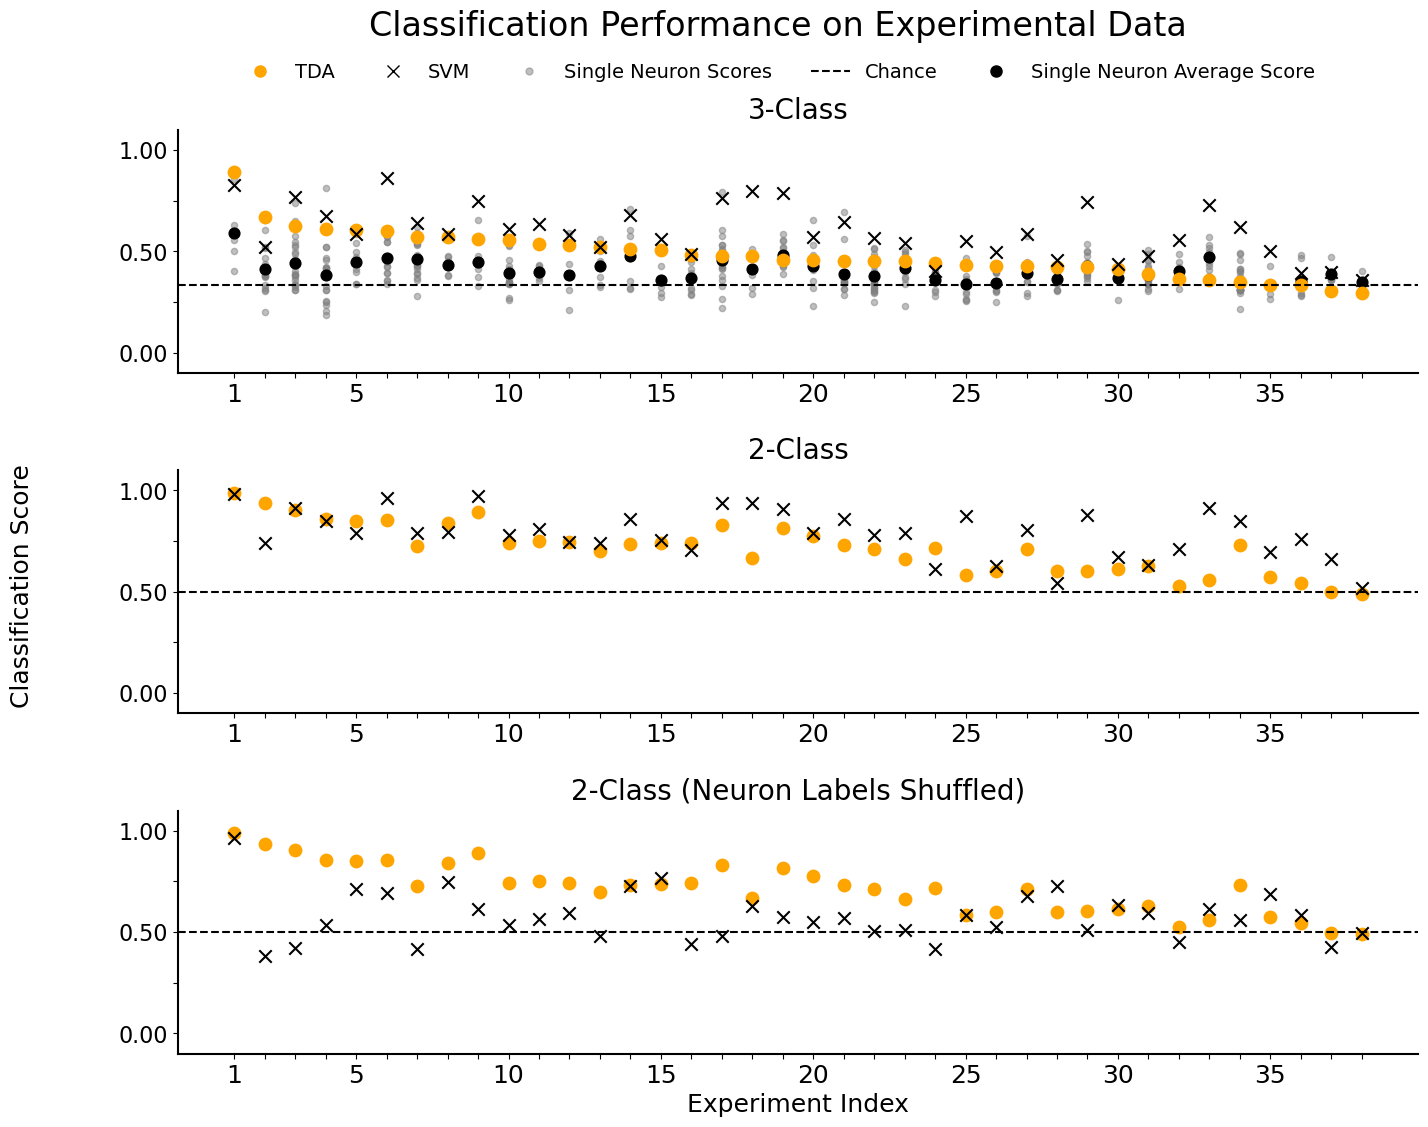

In [64]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import MaxNLocator, FuncFormatter
from matplotlib.lines import Line2D

# ---- font controls ----
legend_font_size = 14
font_size = 30
axes_titlesize = 20
axes_labelsize = 18
xtick_labelsize = 18
ytick_labelsize = 16
figure_titlesize = 24

plt.rcParams.update({
    "font.size": font_size,
    "axes.titlesize": axes_titlesize,
    "axes.labelsize": axes_labelsize,
    "xtick.labelsize": xtick_labelsize,
    "ytick.labelsize": ytick_labelsize,
    "legend.fontsize": legend_font_size,
    "figure.titlesize": figure_titlesize,
})

# --- 1. Order the Experiments based on TDA 3-Class Scores ---
# Sort the 3-class dataframe descending by TDA score
sorted_3class_df = MD_scores_table_3class.sort_values(by="TDA_Mean", ascending=False).reset_index(drop=True)

# Extract the sorted sequence of Mouse/Date tuples to use as our "master key"
experiments = list(zip(sorted_3class_df["Mouse"], sorted_3class_df["Date"]))
x_ticks = np.arange(len(experiments))

# --- 2. Prepare other dataframes for easy lookup ---
# Index the other dataframes by Mouse and Date so we can query them efficiently
df_neurons = neuron_scores_df.set_index(['Mouse', 'Date'])
df_perm = results_permutation_invariance.set_index(['Mouse', 'Date'])

# Find all columns that contain individual neuron scores
neuron_cols = [c for c in df_neurons.columns if c.startswith('Neuron_') and c.endswith('_Score')]

# Extract data for Panels 2 and 3 into lists using our master order
tda_2class, svm_2class = [], []
tda_2class_shuff, svm_2class_shuff = [], []
avg_ind_scores = []

for m, d in experiments:
    # 2-class normal and shuffled data
    if (m, d) in df_perm.index:
        perm_row = df_perm.loc[(m, d)]
        tda_2class.append(perm_row["TDA_normal_mean"])
        svm_2class.append(perm_row["SVM_normal_mean"])
        tda_2class_shuff.append(perm_row["TDA_shuffled_mean"])
        svm_2class_shuff.append(perm_row["SVM_shuffled_mean"])
    else:
        tda_2class.append(np.nan); svm_2class.append(np.nan)
        tda_2class_shuff.append(np.nan); svm_2class_shuff.append(np.nan)
        
    # Mean single neuron scores
    if (m, d) in df_neurons.index:
        avg_ind_scores.append(df_neurons.loc[(m, d), "Mean_Neuron_Score"])
    else:
        avg_ind_scores.append(np.nan)


# --- 3. Build the Plot ---
# 3 stacked panels with shared y-axis
# fig, axs = plt.subplots(3, 1, figsize=(16, 10), sharex=True, sharey=True, constrained_layout=False)

# fig.suptitle("Classification Performance on Experimental Data", fontsize=figure_titlesize)
# fig.subplots_adjust(top=0.9, hspace=0.15)  # leave room for title + legend

fig, axs = plt.subplots(3, 1, figsize=(16, 12), sharex=True, sharey=True, constrained_layout=False)

fig.suptitle("Classification Performance on Experimental Data", fontsize=figure_titlesize, y=0.98)
fig.subplots_adjust(top=0.88, hspace=0.40)
fig.supylabel("Classification Score", fontsize=axes_labelsize)

# X-axis label formatting: show x labels every 5
tick_positions = np.arange(len(experiments))
tick_labels = [str(i + 1) if (i == 0 or (i + 1) % 5 == 0) else "" for i in range(len(experiments))]

# common y formatting
def selected_y_tick_formatter(y, pos):
    if np.isclose(y, 0.0):
        return "0.00"
    elif np.isclose(y, 0.5):
        return "0.50"
    elif np.isclose(y, 1.0):
        return "1.00"
    else:
        return ""
for ax in axs:
    ax.set_ylim(-0.1, 1.1)
    # ax.grid(axis="both", linestyle="-", alpha=0.3)

    # Keep the current tick positions
    ax.yaxis.set_major_locator(MaxNLocator(nbins=5))

    # Only display selected y-tick labels
    ax.yaxis.set_major_formatter(FuncFormatter(selected_y_tick_formatter))




# --- Panel 1: 3-class data ---
ax1 = axs[0]
ax1.set_title("3-Class",pad = 8)
chance_3class = 1 / 3
ax1.axhline(y=chance_3class, color="black", linestyle="--", label="Chance")

# Plot individual neuron score scatter points
for i, (m, d) in enumerate(experiments):
    if (m, d) in df_neurons.index:
        # Extract the neuron scores for this row, dropping any NaNs
        scores = df_neurons.loc[(m, d), neuron_cols].dropna().values
        x_values = [i] * len(scores)

        if i == 0:
            ax1.scatter(x_values, scores, color="gray", alpha=0.5, s=20, label="Ind. Neuron Scores")
        else:
            ax1.scatter(x_values, scores, color="gray", alpha=0.5, s=20)

# Overlay the averages and main algorithm scores
ax1.scatter(x_ticks, avg_ind_scores, color="black", s=60, label="Avg. Ind Neuron Score")
ax1.scatter(x_ticks, sorted_3class_df["TDA_Mean"], color="orange", marker="o", s=80, label="TDA")
ax1.scatter(x_ticks, sorted_3class_df["SVM_Mean"], color="black", marker="x", s=80, label="SVM")


# --- Panel 2: 2-Class data ---
ax2 = axs[1]
ax2.set_title("2-Class",pad = 8)
chance_2class = 1 / 2
ax2.axhline(y=chance_2class, color="black", linestyle="--", label="Chance")
ax2.scatter(x_ticks, tda_2class, color="orange", marker="o", s=80, label="TDA")
ax2.scatter(x_ticks, svm_2class, color="black", marker="x", s=80, label="SVM")


# --- Panel 3: 2-Class Shuffled data ---
ax3 = axs[2]
ax3.set_title("2-Class (Neuron Labels Shuffled)", pad=8)
ax3.set_xlabel("Experiment Index")
ax3.axhline(y=chance_2class, color="black", linestyle="--", label="Chance")
ax3.scatter(x_ticks, tda_2class_shuff, color="orange", marker="o", s=80, label="TDA (shuffled)")
ax3.scatter(x_ticks, svm_2class_shuff, color="black", marker="x", s=80, label="SVM (shuffled)")

# Apply formatted x-ticks only to the bottom plot
ax3.set_xticks(tick_positions)
ax3.set_xticklabels(tick_labels, rotation=0)


# --- Legend ---
legend_handles = [
    Line2D([0], [0], marker="o", color="orange", linestyle="None", markersize=8, label="TDA"),
    Line2D([0], [0], marker="x", color="black", linestyle="None", markersize=8, label="SVM"),
    Line2D([0], [0], marker="o", color="gray", linestyle="None", markersize=5, alpha=0.5, label="Single Neuron Scores"),
    Line2D([0], [0], color="black", linestyle="--", label="Chance"),
    Line2D([0], [0], marker="o", color="black", linestyle="None", markersize=8, label="Single Neuron Average Score"),
]

fig.legend(
    handles=legend_handles,
    loc="upper center",
    ncol=5,
    frameon=False,
    bbox_to_anchor=(0.5, 0.95),
    fontsize=legend_font_size,
)

# Remove top and right spines for all subplots
for ax in axs:
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

    # Optional: make remaining axes slightly thicker
    ax.spines['left'].set_linewidth(1.5)
    ax.spines['bottom'].set_linewidth(1.5)

    # Ensure ticks only on visible axes
    ax.yaxis.set_ticks_position('left')
    ax.xaxis.set_ticks_position('bottom')

plt.savefig((FIGURE_DIR / 'classification_performance_TDA_SVM_3panels_refined.pdf'), format="pdf", bbox_inches="tight")
plt.show()

# Statistical Signifance TDA vs Individual neurons

In [39]:
import pandas as pd
import numpy as np
from scipy import stats

# Set up dataframe indices for easy lookup
df_tda = MD_scores_table_3class.set_index(['Mouse', 'Date'])
df_neurons = neuron_scores_df.set_index(['Mouse', 'Date'])

# Identify the columns containing the raw data
tda_cols = [f'TDA_Split_{i}' for i in range(1, 21)]
neuron_cols = [c for c in df_neurons.columns if c.startswith('Neuron_') and c.endswith('_Score')]

# Counters for the final summary
total_experiments = len(df_tda)
significant_experiments = 0
tda_wins = 0
msn_wins = 0

detailed_results_msn = []

print("Running 38 Independent Welch's t-tests (TDA vs Single Neuron 3-Class)...\n")

for (mouse, date), tda_row in df_tda.iterrows():
    
    # 1. Get the 20 TDA split scores
    tda_splits = tda_row[tda_cols].values.astype(float)
    
    # 2. Get the individual neuron scores, dropping NaNs (since N varies by session)
    if (mouse, date) in df_neurons.index:
        neuron_scores = df_neurons.loc[(mouse, date), neuron_cols].dropna().values.astype(float)
    else:
        # If an experiment has no neuron data, we skip the statistical test for it
        continue 
        
    # Skip if there are zero or 1 neurons (variance cannot be calculated)
    if len(neuron_scores) < 2:
        continue

    # 3. Run Welch's t-test (equal_var=False)
    t_stat, p_value = stats.ttest_ind(tda_splits, neuron_scores, equal_var=False)
    
    # 4. Check for significance
    is_significant = p_value < 0.05
    
    # Determine the winner based on the means
    tda_mean = np.mean(tda_splits)
    msn_mean = np.mean(neuron_scores)
    
    winner = "Tie"
    if is_significant:
        significant_experiments += 1
        if tda_mean > msn_mean:
            tda_wins += 1
            winner = "TDA"
        elif msn_mean > tda_mean:
            msn_wins += 1
            winner = "MSN"
            
    # Save the granular data
    detailed_results_msn.append({
        'Mouse': mouse,
        'Date': date,
        'Num_Neurons': len(neuron_scores),
        'TDA_Mean': tda_mean,
        'MSN_Mean': msn_mean,
        't_stat': t_stat,
        'p_value': p_value,
        'Significant': is_significant,
        'Winner': winner
    })

tda_win_pct = (tda_wins / significant_experiments) * 100 if significant_experiments > 0 else 0
msn_win_pct = (msn_wins / significant_experiments) * 100 if significant_experiments > 0 else 0

print("--- SUMMARY ---")
print(f"Across the {total_experiments} experiments, the two methods showed a statistically significant difference in {significant_experiments} of {total_experiments} experiments (Welch's t-test, p < 0.05).")
print(f"In these cases, the network classification score (TDA) outperformed the single neuron average {tda_wins} of {significant_experiments} times ({tda_win_pct:.0f}%), whereas the mean single neuron accuracy was significantly greater than the network accuracy {msn_wins} of {significant_experiments} times ({msn_win_pct:.0f}%).")

# Optional: Convert detailed results to a DataFrame for easy viewing
tda_vs_msn_stats_df = pd.DataFrame(detailed_results_msn)
tda_vs_msn_stats_df.head()

Running 38 Independent Welch's t-tests (TDA vs Single Neuron 3-Class)...

--- SUMMARY ---
Across the 38 experiments, the two methods showed a statistically significant difference in 20 of 38 experiments (Welch's t-test, p < 0.05).
In these cases, the network classification score (TDA) outperformed the single neuron average 19 of 20 times (95%), whereas the mean single neuron accuracy was significantly greater than the network accuracy 1 of 20 times (5%).


,Mouse,Date,Num_Neurons,TDA_Mean,MSN_Mean,t_stat,p_value,Significant,Winner
0,CB279,121621,7,0.511111,0.478307,0.533612,0.610631,False,Tie
1,CB279,121421,9,0.476000,0.410893,2.109303,0.049235,True,TDA
2,CB279,122021,8,0.603704,0.447222,4.342100,0.001282,True,TDA
3,CB278,121521,11,0.458333,0.483056,-0.926399,0.363308,False,Tie
4,CB278,121721,18,0.477778,0.457044,0.565659,0.575964,False,Tie
